# DNABERT-2 Probing: Linear & MLP (v2 — with Validation Set)

**Changes from v1**:
- Train embeddings split into `train (80%) / val (20%)` using `train_test_split`
- Best (layer × pooling) config selected by **val F1**, NOT test F1
- Test set used **exactly once** to report final numbers
- All other logic (seeds, metrics, plots) unchanged

**Why this matters**: In v1, 144 (layer × pooling × seed × probe) combinations were all
evaluated on the test set, and the best was selected — this is implicit test-set selection bias.
The correction: use val to pick the best config, then evaluate that config on test.

**Experiment matrix** (per probe type): 8 layers × 3 poolings × 3 seeds = 72 runs
**Total**: 72 × 2 probe types = **144 runs** (same as before, but now split into val-select + test-report)

| Probe | Architecture | Parameters |
|-------|-------------|------------|
| Linear | 768 → 2 | 1,538 |
| MLP | 768 → 256 → 32 → 2 | 205,090 |

**Data split**:
```
Original train (27,097)  →  train_sub (21,678, 80%) + val (5,419, 20%)
Original test  (9,034)   →  test (untouched, used once at the end)
```

## 0. Imports & Config

In [1]:
import torch
import torch.nn as nn
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, matthews_corrcoef
from tqdm import tqdm

# ============ CONFIG ============
CACHE_DIR   = './embedding_cache'
DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
HIDDEN_DIM  = 768
NUM_CLASSES = 2
BATCH_SIZE  = 256
SEEDS       = [42, 123, 456]
VAL_RATIO   = 0.2    # 20% of train → val
SPLIT_SEED  = 42     # fixed seed for train/val split (same across all experiments)

PROBE_CONFIG = {
    'linear': {'lr': 1e-3, 'epochs': 10},
    'mlp':    {'lr': 1e-3, 'epochs': 20},
}
# ================================

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

LAYER_KEYS  = [0, 1, 3, 6, 8, 10, 12, 'avg_last4']
POOL_NAMES  = ['mean', 'max', 'cls']
PROBE_TYPES = ['linear', 'mlp']

print(f'Device: {DEVICE}')
print(f'Val ratio: {VAL_RATIO} (split seed={SPLIT_SEED})')
print(f'Total experiments: {len(LAYER_KEYS)*len(POOL_NAMES)*len(SEEDS)*len(PROBE_TYPES)}')

Device: cuda
Val ratio: 0.2 (split seed=42)
Total experiments: 144


## 1. Load Cache & Create Train/Val Split

**Key design**: The train/val split is done **once** with a fixed seed, then reused across all
(layer × pooling × probe) experiments. This ensures the split is identical for every comparison.

In [2]:
def load_cache(split_name, layer_key, pool_name, cache_dir=CACHE_DIR):
    emb    = np.load(os.path.join(cache_dir, f'{split_name}_layer{layer_key}_{pool_name}.npy'))
    labels = np.load(os.path.join(cache_dir, f'{split_name}_labels.npy'))
    return emb, labels


def get_split_indices(n_train, val_ratio=VAL_RATIO, seed=SPLIT_SEED):
    """
    Returns fixed train_idx and val_idx for a dataset of size n_train.
    Called once; same indices reused across all (layer × pooling) combos.
    """
    idx = np.arange(n_train)
    train_idx, val_idx = train_test_split(
        idx,
        test_size=val_ratio,
        random_state=seed,
        stratify=np.load(os.path.join(CACHE_DIR, 'train_labels.npy'))  # stratified split
    )
    return train_idx, val_idx


# Compute split indices once
full_train_labels = np.load(os.path.join(CACHE_DIR, 'train_labels.npy'))
n_train_full = len(full_train_labels)
TRAIN_IDX, VAL_IDX = get_split_indices(n_train_full)

print(f'Full train: {n_train_full}')
print(f'  → train_sub: {len(TRAIN_IDX)}  ({len(TRAIN_IDX)/n_train_full*100:.0f}%)')
print(f'  → val:       {len(VAL_IDX)}  ({len(VAL_IDX)/n_train_full*100:.0f}%)')
print(f'Train label dist: {np.bincount(full_train_labels[TRAIN_IDX])}')
print(f'Val   label dist: {np.bincount(full_train_labels[VAL_IDX])}')

# Verify test set is untouched
test_labels = np.load(os.path.join(CACHE_DIR, 'test_labels.npy'))
print(f'Test  label dist: {np.bincount(test_labels)}  (untouched)')

Full train: 27097
  → train_sub: 21677  (80%)
  → val:       5420  (20%)
Train label dist: [ 9884 11793]
Val   label dist: [2471 2949]
Test  label dist: [4119 4915]  (untouched)


## 2. Probe Models (unchanged from v1)

In [3]:
class LinearProbe(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.linear = nn.Linear(input_dim, num_classes)
    def forward(self, x):
        return self.linear(x)


class MLPProbe(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 32),
            nn.ReLU(),
            nn.Linear(32, num_classes),
        )
    def forward(self, x):
        return self.model(x)


PROBE_CLASSES = {'linear': LinearProbe, 'mlp': MLPProbe}

for name, cls in PROBE_CLASSES.items():
    n = sum(p.numel() for p in cls(HIDDEN_DIM, NUM_CLASSES).parameters())
    print(f'{name:>6s}: {n:>8,} parameters')

linear:    1,538 parameters
   mlp:  205,154 parameters


## 3. Train & Evaluate (now returns val + test metrics separately)

In [4]:
def set_all_seeds(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)


def compute_metrics(preds, labels):
    return {
        'accuracy': accuracy_score(labels, preds),
        'f1':       f1_score(labels, preds, average='macro'),
        'mcc':      matthews_corrcoef(labels, preds),
    }


def train_and_evaluate(train_emb, train_labels,
                       val_emb,   val_labels,
                       test_emb,  test_labels,
                       probe_type='linear', seed=42):
    """
    Train probe on train_sub, evaluate on both val and test.
    Returns: dict with val_* and test_* metrics.
    """
    set_all_seeds(seed)
    cfg = PROBE_CONFIG[probe_type]

    X_train = torch.tensor(train_emb,  dtype=torch.float32)
    y_train = torch.tensor(train_labels, dtype=torch.long)
    X_val   = torch.tensor(val_emb,    dtype=torch.float32)
    y_val   = torch.tensor(val_labels,   dtype=torch.long)
    X_test  = torch.tensor(test_emb,   dtype=torch.float32)
    y_test  = torch.tensor(test_labels,  dtype=torch.long)

    g = torch.Generator().manual_seed(seed)
    train_dl = DataLoader(TensorDataset(X_train, y_train),
                          batch_size=BATCH_SIZE, shuffle=True, generator=g)

    probe = PROBE_CLASSES[probe_type](HIDDEN_DIM, NUM_CLASSES).to(DEVICE)
    optimizer = torch.optim.Adam(probe.parameters(), lr=cfg['lr'])
    criterion = nn.CrossEntropyLoss()

    # Training
    probe.train()
    for _ in range(cfg['epochs']):
        for xb, yb in train_dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            criterion(probe(xb), yb).backward()
            optimizer.step()

    # Evaluation
    probe.eval()
    with torch.no_grad():
        val_preds  = probe(X_val.to(DEVICE)).argmax(dim=1).cpu().numpy()
        test_preds = probe(X_test.to(DEVICE)).argmax(dim=1).cpu().numpy()

    val_metrics  = compute_metrics(val_preds,  y_val.numpy())
    test_metrics = compute_metrics(test_preds, y_test.numpy())

    return {
        **{f'val_{k}':  v for k, v in val_metrics.items()},
        **{f'test_{k}': v for k, v in test_metrics.items()},
    }


print('train_and_evaluate() defined (returns val + test metrics).')

train_and_evaluate() defined (returns val + test metrics).


## 4. Run All Experiments

In [5]:
results = []
total = len(PROBE_TYPES) * len(LAYER_KEYS) * len(POOL_NAMES) * len(SEEDS)
pbar = tqdm(total=total, desc='Running all probes')

for probe_type in PROBE_TYPES:
    for layer_key in LAYER_KEYS:
        for pool_name in POOL_NAMES:
            # Load full train embeddings and split
            full_emb, full_labels = load_cache('train', layer_key, pool_name)
            train_emb = full_emb[TRAIN_IDX];    train_labels = full_labels[TRAIN_IDX]
            val_emb   = full_emb[VAL_IDX];      val_labels   = full_labels[VAL_IDX]

            # Load test
            test_emb, test_labels = load_cache('test', layer_key, pool_name)

            for seed in SEEDS:
                metrics = train_and_evaluate(
                    train_emb, train_labels,
                    val_emb,   val_labels,
                    test_emb,  test_labels,
                    probe_type=probe_type, seed=seed
                )
                metrics.update({'probe': probe_type, 'layer': layer_key,
                                'pooling': pool_name, 'seed': seed})
                results.append(metrics)
                pbar.update(1)

pbar.close()
print(f'Done! {len(results)} runs completed.')

Running all probes: 100%|████████████████████████████████████████████████████████████| 144/144 [06:01<00:00,  2.51s/it]

Done! 144 runs completed.


## 5. Select Best Config on Val, Report on Test

**Correct protocol**:
1. Average val F1 across seeds for each (probe × layer × pooling)
2. Pick the config with **highest val F1** → this is the "selected" config
3. Report the **test F1** of that selected config (averaged across seeds)

In [6]:
df = pd.DataFrame(results)

# Average over seeds
df_mean = df.groupby(['probe', 'layer', 'pooling']).agg(
    val_f1_mean  =('val_f1',       'mean'),
    val_f1_std   =('val_f1',       'std'),
    val_acc_mean =('val_accuracy', 'mean'),
    val_mcc_mean =('val_mcc',      'mean'),
    test_f1_mean =('test_f1',      'mean'),
    test_f1_std  =('test_f1',      'std'),
    test_acc_mean=('test_accuracy','mean'),
    test_acc_std =('test_accuracy','std'),
    test_mcc_mean=('test_mcc',     'mean'),
    test_mcc_std =('test_mcc',     'std'),
).reset_index()

print('=' * 65)
print('FINAL RESULTS — config selected by VAL F1, reported on TEST')
print('=' * 65)

for pt in PROBE_TYPES:
    sub = df_mean[df_mean['probe'] == pt]

    # ★ Select best config by VAL F1
    best_idx = sub['val_f1_mean'].idxmax()
    best = sub.loc[best_idx]

    print(f'\n--- {pt.upper()} Probe ---')
    print(f'  Best config (by val F1):  layer={best["layer"]}, pooling={best["pooling"]}')
    print(f'  Val  F1  = {best["val_f1_mean"]:.4f} ± {best["val_f1_std"]:.4f}')
    print(f'  Test F1  = {best["test_f1_mean"]:.4f} ± {best["test_f1_std"]:.4f}  ← final number')
    print(f'  Test Acc = {best["test_acc_mean"]:.4f} ± {best["test_acc_std"]:.4f}')
    print(f'  Test MCC = {best["test_mcc_mean"]:.4f} ± {best["test_mcc_std"]:.4f}')

FINAL RESULTS — config selected by VAL F1, reported on TEST

--- LINEAR Probe ---
  Best config (by val F1):  layer=3, pooling=mean
  Val  F1  = 0.8577 ± 0.0004
  Test F1  = 0.8473 ± 0.0006  ← final number
  Test Acc = 0.8474 ± 0.0006
  Test MCC = 0.7019 ± 0.0010

--- MLP Probe ---
  Best config (by val F1):  layer=3, pooling=mean
  Val  F1  = 0.9103 ± 0.0037
  Test F1  = 0.9121 ± 0.0031  ← final number
  Test Acc = 0.9125 ± 0.0030
  Test MCC = 0.8257 ± 0.0067


## 6. Full Results Table (Val F1 for config selection reference)

In [7]:
for pt in PROBE_TYPES:
    sub = df_mean[df_mean['probe'] == pt].copy()
    sub['Val F1']  = sub.apply(lambda r: f"{r.val_f1_mean:.4f} ± {r.val_f1_std:.4f}", axis=1)
    sub['Test F1'] = sub.apply(lambda r: f"{r.test_f1_mean:.4f} ± {r.test_f1_std:.4f}", axis=1)
    sub['Test MCC']= sub.apply(lambda r: f"{r.test_mcc_mean:.4f} ± {r.test_mcc_std:.4f}", axis=1)
    print(f'\n{pt.upper()} PROBE — full table')
    print(sub[['layer','pooling','Val F1','Test F1','Test MCC']].to_string(index=False))

# Save
df.to_csv('probe_results_v2.csv', index=False)
print('\nSaved to probe_results_v2.csv')


LINEAR PROBE — full table
    layer pooling          Val F1         Test F1        Test MCC
        0     cls 0.3524 ± 0.0000 0.3524 ± 0.0000 0.0000 ± 0.0000
        0     max 0.7888 ± 0.0007 0.7826 ± 0.0016 0.5735 ± 0.0028
        0    mean 0.8166 ± 0.0006 0.8070 ± 0.0006 0.6237 ± 0.0018
        1     cls 0.7548 ± 0.0010 0.7441 ± 0.0028 0.4924 ± 0.0087
        1     max 0.8138 ± 0.0004 0.8026 ± 0.0015 0.6177 ± 0.0064
        1    mean 0.8389 ± 0.0008 0.8280 ± 0.0004 0.6629 ± 0.0009
        3     cls 0.7620 ± 0.0028 0.7509 ± 0.0047 0.5026 ± 0.0107
        3     max 0.8303 ± 0.0027 0.8191 ± 0.0028 0.6552 ± 0.0071
        3    mean 0.8577 ± 0.0004 0.8473 ± 0.0006 0.7019 ± 0.0010
        6     cls 0.8334 ± 0.0011 0.8253 ± 0.0020 0.6595 ± 0.0088
        6     max 0.8358 ± 0.0030 0.8313 ± 0.0024 0.6804 ± 0.0044
        6    mean 0.8527 ± 0.0021 0.8503 ± 0.0007 0.7105 ± 0.0065
        8     cls 0.8163 ± 0.0042 0.8181 ± 0.0007 0.6417 ± 0.0039
        8     max 0.8273 ± 0.0020 0.8211 ± 0.0028

## 7. Val vs Test F1 Correlation Plot

This plot verifies that val F1 is a **reliable proxy** for test F1 — if the points lie on the
diagonal, val selection is trustworthy. Large deviations would indicate distribution shift.

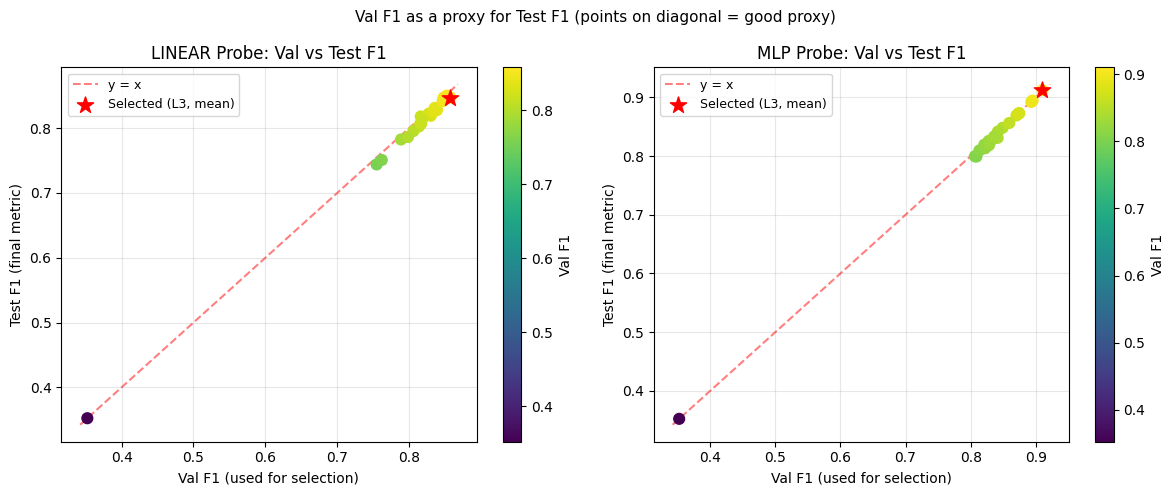

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, pt in zip(axes, PROBE_TYPES):
    sub = df_mean[df_mean['probe'] == pt]

    scatter = ax.scatter(sub['val_f1_mean'], sub['test_f1_mean'],
                         c=sub['val_f1_mean'], cmap='viridis', s=60, zorder=3)

    # Diagonal reference line
    lims = [min(sub['val_f1_mean'].min(), sub['test_f1_mean'].min()) - 0.01,
            max(sub['val_f1_mean'].max(), sub['test_f1_mean'].max()) + 0.01]
    ax.plot(lims, lims, 'r--', alpha=0.5, label='y = x')

    # Mark the selected best config
    best_idx = sub['val_f1_mean'].idxmax()
    best = sub.loc[best_idx]
    ax.scatter(best['val_f1_mean'], best['test_f1_mean'],
               color='red', s=150, zorder=5, marker='*',
               label=f'Selected (L{best["layer"]}, {best["pooling"]})')

    ax.set_xlabel('Val F1 (used for selection)')
    ax.set_ylabel('Test F1 (final metric)')
    ax.set_title(f'{pt.upper()} Probe: Val vs Test F1')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.colorbar(scatter, ax=ax, label='Val F1')

plt.suptitle('Val F1 as a proxy for Test F1 (points on diagonal = good proxy)',
             fontsize=11)
plt.tight_layout()
plt.savefig('val_vs_test_f1.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Layer Analysis Plot (using Test F1 of val-selected config per layer)

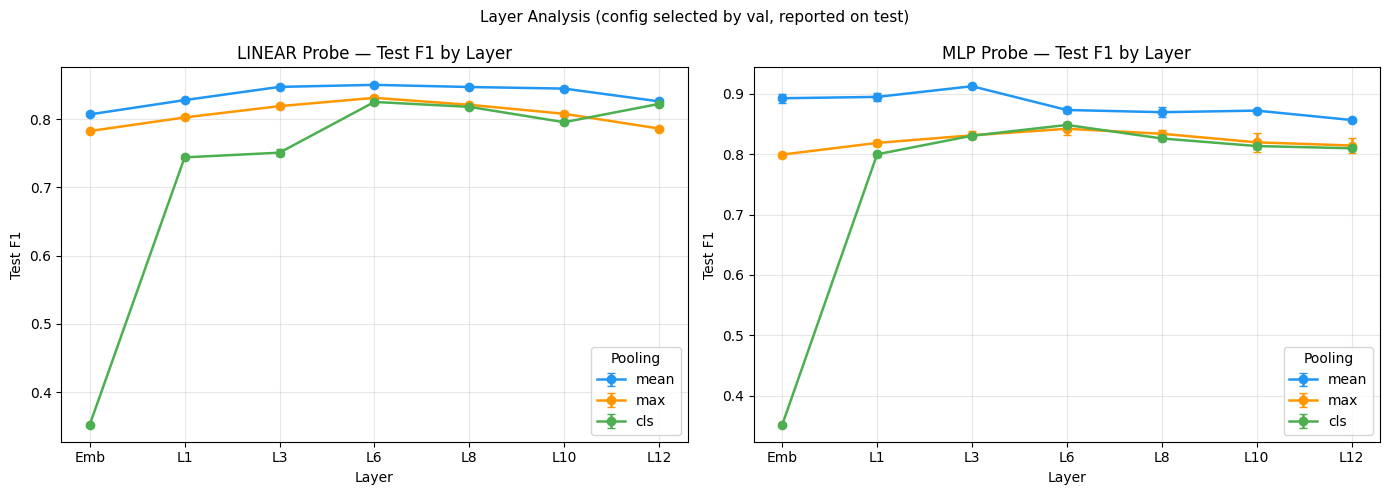

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
layer_order = [0, 1, 3, 6, 8, 10, 12]
x_labels    = ['Emb', 'L1', 'L3', 'L6', 'L8', 'L10', 'L12']
colors = {'mean': '#2196F3', 'max': '#FF9800', 'cls': '#4CAF50'}

for ax, pt in zip(axes, PROBE_TYPES):
    sub = df_mean[(df_mean['probe'] == pt) & (df_mean['layer'].isin(layer_order))]
    for pool in POOL_NAMES:
        pool_sub = sub[sub['pooling'] == pool].copy()
        pool_sub['layer_idx'] = pool_sub['layer'].apply(lambda x: layer_order.index(x))
        pool_sub = pool_sub.sort_values('layer_idx')
        ax.errorbar(pool_sub['layer_idx'], pool_sub['test_f1_mean'],
                    yerr=pool_sub['test_f1_std'],
                    label=pool, color=colors[pool], marker='o', linewidth=1.8, capsize=3)

    ax.set_xticks(range(len(layer_order)))
    ax.set_xticklabels(x_labels)
    ax.set_xlabel('Layer')
    ax.set_ylabel('Test F1')
    ax.set_title(f'{pt.upper()} Probe — Test F1 by Layer')
    ax.legend(title='Pooling')
    ax.grid(True, alpha=0.3)

plt.suptitle('Layer Analysis (config selected by val, reported on test)', fontsize=11)
plt.tight_layout()
plt.savefig('layer_analysis_v2.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Summary — Comparison with v1

Compare results with v1 to quantify the selection bias introduced by using test for selection.

In [10]:
print('=' * 60)
print('SUMMARY — Val-selected vs v1 (test-selected)')
print('=' * 60)

# v1 results (hardcoded from Notebook 02 v1 output)
v1 = {
    'linear': {'layer': 6,  'pooling': 'mean', 'test_f1': 0.8542, 'test_mcc': 0.7137},
    'mlp':    {'layer': 3,  'pooling': 'mean', 'test_f1': 0.9277, 'test_mcc': 0.8508},
}

for pt in PROBE_TYPES:
    sub  = df_mean[df_mean['probe'] == pt]
    best = sub.loc[sub['val_f1_mean'].idxmax()]

    v1_f1  = v1[pt]['test_f1']
    v2_f1  = best['test_f1_mean']
    delta  = v2_f1 - v1_f1

    print(f'\n{pt.upper()} Probe')
    print(f'  v1 (test-selected): layer={v1[pt]["layer"]}, pooling={v1[pt]["pooling"]}, Test F1={v1_f1:.4f}')
    print(f'  v2 (val-selected):  layer={best["layer"]},  pooling={best["pooling"]},  Test F1={v2_f1:.4f}')
    print(f'  Selection bias: {delta:+.4f} F1')
    if abs(delta) < 0.005:
        print(f'  → Negligible bias (< 0.005): val and test rankings are consistent ✓')
    else:
        print(f'  → Noticeable bias: discuss in paper')

SUMMARY — Val-selected vs v1 (test-selected)

LINEAR Probe
  v1 (test-selected): layer=6, pooling=mean, Test F1=0.8542
  v2 (val-selected):  layer=3,  pooling=mean,  Test F1=0.8473
  Selection bias: -0.0069 F1
  → Noticeable bias: discuss in paper

MLP Probe
  v1 (test-selected): layer=3, pooling=mean, Test F1=0.9277
  v2 (val-selected):  layer=3,  pooling=mean,  Test F1=0.9121
  Selection bias: -0.0156 F1
  → Noticeable bias: discuss in paper
